# Problem set #2
Define a random variable, X, that has a continuous, uniform distribution on the interval [1,10].

### **1) What is the mean of X?**

The mean of X is 
$
E[X]=\frac{1}{9}\int_1^{10}x\,dx
=\frac{1}{9}\left[\frac{x^2}{2}\right]_1^{10}
=5.5
$

### **2) What is the second moment of X?**

The second moment of X is $E[X^2]=\frac{1}{9}\int_1^{10}x^2\,dx$

$=\frac{1}{9}\left[\frac{x^3}{3}\right]_1^{10}
=\frac{1000-1}{27}
=37$

### **3) What is the variance of X?**

Variance of X can be calculated as 

${Var}(X)=E[X^2]-(E[X])^2
=37-(5.5)^2=37-30.25=6.75$

(Hint: use the answers from questions 1 and 2 for question 3) 


### **Simulate 10 random draws from this distribution** 
- For each set of 10 random draws, calculate the mean  of those 10 numbers. 
- Now, do this for 2000 iterations, keeping track of the mean on each iteration.

In [3]:
import numpy as np

total = 0
for i in range(10):
    x = np.random.uniform(1,10)
    print(x)
    total = total + x 

mean = total/10
print("mean of 10 random draws:", mean)

7.995118684482893
3.540758163463071
1.161977324903237
5.943073728175071
8.581598066168393
6.440642174378651
5.980120998779682
3.65470313067098
6.577318320624178
3.8541569414144994
mean of 10 random draws: 5.372946753306066


In [4]:
means = []
draws = 10
iterations = 2000
for _ in range(iterations):
    total = 0

    for i in range(draws):
        x = np.random.uniform(1, 10)
        total = total + x   
    
    mean = total / draws
    means.append(mean)

means_array = np.array(means)

In [5]:
means_array

array([6.7297425 , 6.62797255, 4.87882337, ..., 5.80507302, 6.23721374,
       3.63150812], shape=(2000,))

### **4) Make a histogram of the means**


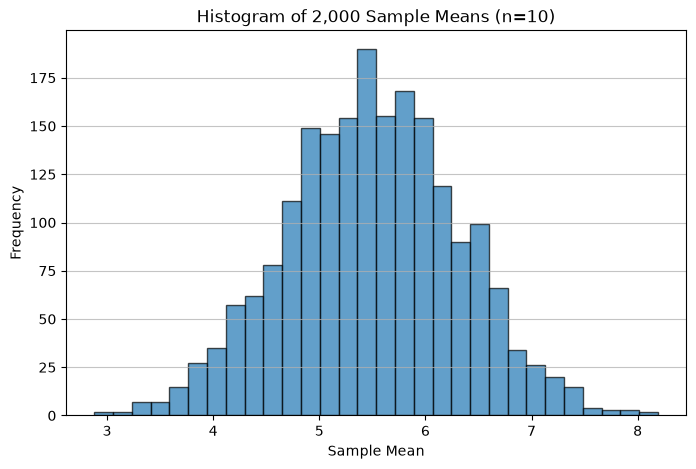

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(means_array, bins=30, edgecolor='black', alpha=0.7)

plt.title('Histogram of 2,000 Sample Means (n=10)')
plt.xlabel('Sample Mean')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

plt.show()



### 5) What is the mean, on average? (The mean of the 2000 sample means)





In [8]:
mean=np.mean(means_array)
mean

np.float64(5.498436245945101)

### 7a) On average (across the 2000 iterations), how different is the mean of 10 random draws from E(X) (the answer to problem #1)? 
On average, the mean is close to 0 (see below)



In [10]:
mae = np.mean(np.abs(5.5 - mean))
mae


np.float64(0.0015637540548993911)

### 7b) How do you think this would change if instead of taking 10 draws at a time, you took 20 or 100?

I think the less number of draws we take, the higher the standard error gets. 

### 7c) Would you like to have a way of calculating this stuff (parts 7a and 7b)  without having to do all of these simulations and without having to assume  a specific distribution (in this case uniform(1,10))?

I would. 

### 8) Often in neuroscience, investigators "normalize" variables by dividing each by their maximum, mean, or sum. This normalization has interesting consequences for the joint distribution of these variables.

Consider this probability distribution P(X=x, Y=y):
 
   1| 0.1  0.1  0.1
 y 2| 0.1  0.2  0.1
   3| 0.1  0.1  0.1
     ---------------
       1    2    3 
            x

 ### 8a) What is the correlation between X and Y?

We know that covariance is calculated as 
$
\operatorname{Cov}(X,Y)
=E[XY]-E[X]E[Y]
$

And can caluculate $E[X] and E[Y]$ (which are the same in this matrix using the marginal expectations $1*0.3 + 2*0.4 + 3*0.3 = 2$

Then we can calculate 
$E[XY] as 
E[XY]=0.1(1+2+3)^2+0.1(2\cdot2)
=3.6+0.4=4$

Which means 
$
\operatorname{Cov}(X,Y)
=E[XY]-E[X]E[Y] = 4 - 2(2) = 0
$

 ### 8b) What is the correlation between X' and Y'?
 *Define the normalized version of X and Y as $X' = \frac{X}{X+Y}$ and $Y' = \frac{Y}{X+Y}$.*

 After normalization, $X' + Y' = \frac{X+Y}{X+Y} = 1$ which rearranged gives us $Y' = 1-X'$ which is a negative correlation